# Revio Intelligence — AI Review Analysis PoC
**Cynbit Technologies | AI/ML Engineer Intern Assessment**

## Objective
Demonstrate a lightweight review-intelligence workflow that:
1. Classifies customer reviews as Positive, Negative, or Neutral.
2. Identifies likely review aspects (delivery, product quality, support, pricing, usability).
3. Prioritizes reviews that may need human attention.
4. Produces a suggested response template for a human reviewer to approve.



In [ ]:
%pip install -q pandas numpy scikit-learn matplotlib seaborn

In [1]:
import re
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

## 2. Create illustrative review data
For a reproducible local demo, the notebook starts with a small labelled dataset. Replace this with permissioned, anonymized customer reviews before any real evaluation.

In [2]:
samples = [
    ("The delivery was fast and the product quality is excellent", "Positive"),
    ("Great customer support, they resolved my issue quickly", "Positive"),
    ("Very easy to use and worth the price", "Positive"),
    ("The app works smoothly and the service is reliable", "Positive"),
    ("Amazing quality and quick delivery, highly recommended", "Positive"),
    ("Support team was helpful and polite", "Positive"),
    ("The price is reasonable and the product is good", "Positive"),
    ("I love the simple interface and fast service", "Positive"),
    ("Delivery was late and the package arrived damaged", "Negative"),
    ("Terrible customer support, nobody responded to my complaint", "Negative"),
    ("The product quality is poor and not worth the money", "Negative"),
    ("The app keeps crashing and is difficult to use", "Negative"),
    ("Overpriced product with disappointing quality", "Negative"),
    ("My order is still missing after several days", "Negative"),
    ("The service was unreliable and the issue remains unresolved", "Negative"),
    ("Payment was taken but my order was not confirmed", "Negative"),
    ("Delivery took longer than expected", "Neutral"),
    ("The product is okay, nothing particularly special", "Neutral"),
    ("The app has a few useful features", "Neutral"),
    ("Customer support replied after two days", "Neutral"),
    ("The price is similar to other products", "Neutral"),
    ("Package arrived yesterday and I have started using it", "Neutral"),
]
df = pd.DataFrame(samples, columns=["review", "sentiment"])
df.head()

,review,sentiment
0,The delivery was fast and the product quality ...,Positive
1,"Great customer support, they resolved my issue...",Positive
2,Very easy to use and worth the price,Positive
3,The app works smoothly and the service is reli...,Positive
4,"Amazing quality and quick delivery, highly rec...",Positive


## 3. Text cleaning and train a baseline sentiment model
We use TF-IDF features with Logistic Regression. A stratified split keeps the three sentiment classes represented in both sets.

In [3]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"<.*?>", " ", text)
    text = re.sub(r"[^a-z0-9\s']", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["clean_review"] = df["review"].apply(clean_text)

X_train, X_test, y_train, y_test = train_test_split(
    df["clean_review"], df["sentiment"],
    test_size=0.30, random_state=42, stratify=df["sentiment"]
)

sentiment_model = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=1, max_features=3000)),
    ("classifier", LogisticRegression(max_iter=1000, class_weight="balanced"))
])

sentiment_model.fit(X_train, y_train)
predictions = sentiment_model.predict(X_test)

print("Hold-out accuracy (tiny illustrative dataset):", round(accuracy_score(y_test, predictions), 3))
print(classification_report(y_test, predictions, zero_division=0))

Hold-out accuracy (tiny illustrative dataset): 0.286
              precision    recall  f1-score   support

    Negative       0.00      0.00      0.00         3
     Neutral       0.00      0.00      0.00         2
    Positive       0.33      1.00      0.50         2

    accuracy                           0.29         7
   macro avg       0.11      0.33      0.17         7
weighted avg       0.10      0.29      0.14         7



## 4. Evaluate the baseline
Because the sample is very small, the scores will be unstable. For a meaningful evaluation, use a larger, representative, independently labelled dataset and report per-class precision, recall, F1 and a confusion matrix.

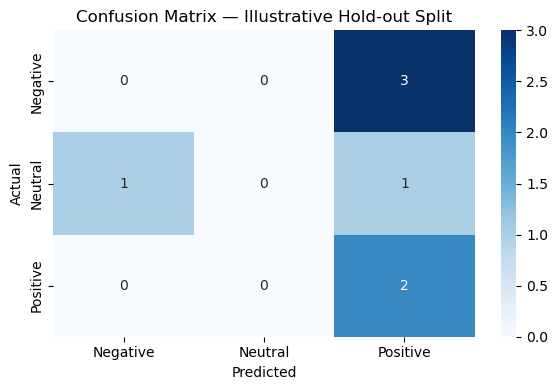

In [4]:
labels = ["Negative", "Neutral", "Positive"]
cm = confusion_matrix(y_test, predictions, labels=labels)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=labels, yticklabels=labels)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix — Illustrative Hold-out Split")
plt.tight_layout()
plt.show()

## 5. Aspect detection (transparent rule-based baseline)
This is a keyword baseline, not a trained aspect model. It can be replaced with multi-label classification or an aspect-based transformer after collecting labelled examples.

In [6]:
ASPECT_KEYWORDS = {
    "Delivery": ["delivery", "shipped", "shipping", "package", "order", "arrived", "missing"],
    "Product quality": ["quality", "product", "damaged", "broken", "poor"],
    "Customer support": ["support", "customer service", "responded", "replied", "complaint", "team"],
    "Pricing": ["price", "pricing", "expensive", "overpriced", "money", "cost", "worth"],
    "Usability": ["app", "interface", "easy to use", "difficult to use", "crashing", "features"]
}

def detect_aspects(text):
    t = clean_text(text)
    found = []
    for aspect, keywords in ASPECT_KEYWORDS.items():
        if any(keyword in t for keyword in keywords):
            found.append(aspect)
    return found if found else ["General experience"]

## 6. Review priority and response recommendation
Priority is a transparent heuristic for triage, not a prediction of customer churn or business risk. A human should review high-priority items before any customer-facing response is sent.

In [7]:
URGENT_TERMS = [
    "fraud", "scam", "charged twice", "payment taken", "missing order",
    "damaged", "broken", "unresolved", "nobody responded", "not received"
]

def assign_priority(review, sentiment):
    text = clean_text(review)
    if sentiment == "Negative" and any(term in text for term in URGENT_TERMS):
        return "High"
    if sentiment == "Negative":
        return "Medium"
    return "Low"

def suggest_response(review, sentiment, aspects, priority):
    if sentiment == "Negative":
        aspect_text = ", ".join(aspects)
        return (
            f"Thank you for bringing this to our attention. We're sorry about your "
            f"experience related to {aspect_text.lower()}. Our team should review "
            f"the details and follow up with an appropriate resolution."
        )
    if sentiment == "Neutral":
        return (
            "Thank you for sharing your feedback. We appreciate your comments "
            "and will use them to improve our service."
        )
    return (
        "Thank you for your positive feedback. We're glad you had a good experience "
        "and appreciate your support."
    )

## 7. Analyze new reviews
Add your own review texts to `new_reviews`. The model predicts sentiment; the aspect and priority modules then produce a triage view.

In [8]:
new_reviews = [
    "My delivery was late and the package arrived damaged. Nobody responded to my complaint.",
    "Excellent product quality and very helpful customer support.",
    "The app has useful features but the price is similar to competitors.",
    "Payment was taken but my order was not confirmed."
]

def analyze_reviews(review_texts):
    cleaned = [clean_text(x) for x in review_texts]
    sentiments = sentiment_model.predict(cleaned)
    rows = []
    for review, sentiment in zip(review_texts, sentiments):
        aspects = detect_aspects(review)
        priority = assign_priority(review, sentiment)
        rows.append({
            "review": review,
            "predicted_sentiment": sentiment,
            "aspects": ", ".join(aspects),
            "priority": priority,
            "suggested_response": suggest_response(review, sentiment, aspects, priority)
        })
    return pd.DataFrame(rows)

results = analyze_reviews(new_reviews)
results

,review,predicted_sentiment,aspects,priority,suggested_response
0,My delivery was late and the package arrived d...,Negative,"Delivery, Product quality, Customer support",High,Thank you for bringing this to our attention. ...
1,Excellent product quality and very helpful cus...,Positive,"Product quality, Customer support",Low,Thank you for your positive feedback. We're gl...
2,The app has useful features but the price is s...,Neutral,"Pricing, Usability",Low,Thank you for sharing your feedback. We apprec...
3,Payment was taken but my order was not confirmed.,Negative,Delivery,Medium,Thank you for bringing this to our attention. ...


## 8. Dashboard-style summary

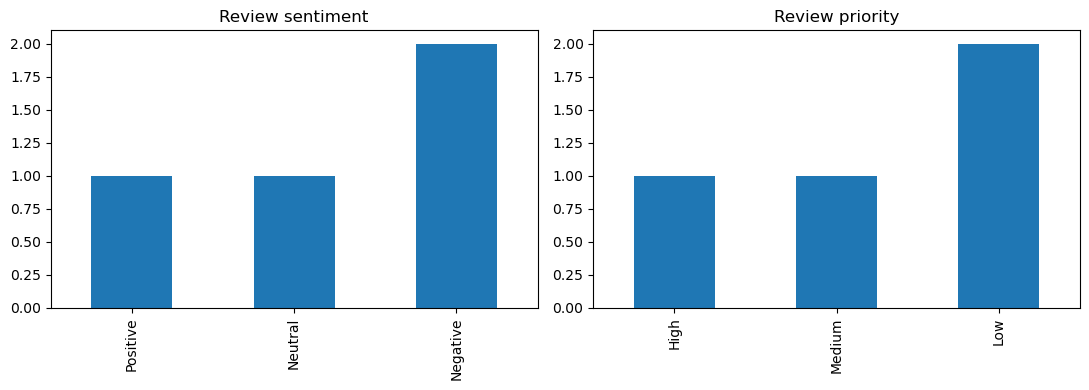

In [9]:
sentiment_counts = results["predicted_sentiment"].value_counts()
priority_counts = results["priority"].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sentiment_counts.reindex(["Positive", "Neutral", "Negative"], fill_value=0).plot(
    kind="bar", ax=axes[0], title="Review sentiment"
)
priority_counts.reindex(["High", "Medium", "Low"], fill_value=0).plot(
    kind="bar", ax=axes[1], title="Review priority"
)
axes[0].set_xlabel("")
axes[1].set_xlabel("")
plt.tight_layout()
plt.show()

## 9. Try your own review
Edit the text below and run the cell to inspect one review.

In [10]:
single_review = "The customer support team did not respond and my payment was taken twice."
analyze_reviews([single_review])

,review,predicted_sentiment,aspects,priority,suggested_response
0,The customer support team did not respond and ...,Negative,Customer support,Medium,Thank you for bringing this to our attention. ...


## 10. Business value, risks and next steps

### Potential value to Revio
- Faster identification of negative feedback that may need attention.
- A structured view of recurring themes such as delivery, quality, support and pricing.
- More consistent first-draft responses, subject to human approval.
- A foundation for trend reporting across locations, products or time periods.

### Risks and controls
- **Small or biased training data:** evaluate on representative, consented and anonymized data.
- **Sarcasm, mixed sentiment and multilingual reviews:** add diverse labelled examples and evaluate language-specific models.
- **Incorrect aspect tags:** measure aspect-level precision/recall and allow manual correction.
- **Unsafe or inaccurate replies:** keep human approval, avoid promises or refunds in generated text, and log edits.
- **Privacy:** minimize personal data, redact identifiers and apply retention/access controls.

### Proposed implementation plan
1. Discovery: confirm review sources, languages, volume, user roles and success metrics.
2. Data: establish consent, anonymization, annotation guidelines and train/validation/test splits.
3. Baseline: benchmark TF-IDF + Logistic Regression against a transformer model.
4. Product integration: expose predictions through an API and display confidence, aspects and priority.
5. Pilot: compare triage time, response time, escalation accuracy and human edit rate against the current workflow.
6. Iterate: monitor drift, feedback and per-language/per-aspect performance.

### Suggested success metrics
- Sentiment macro-F1 and per-class recall.
- Aspect-level precision, recall and F1.
- High-priority complaint recall.
- Median time from review arrival to human triage.
- Percentage of suggested replies accepted or edited by staff.

**Conclusion:** This notebook is a functional baseline demonstration. It does not connect to Cynbit or Revio systems, use proprietary customer data, call an external LLM, or establish production-grade accuracy.